In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = sns.load_dataset('iris')

In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
from sklearn.preprocessing import LabelEncoder

In [5]:
encoder = LabelEncoder()

In [6]:
df['species'] = encoder.fit_transform(df['species'])

In [9]:
df.sample(5)

,sepal_length,sepal_width,petal_length,petal_width,species
47,4.6,3.2,1.4,0.2,0
26,5.0,3.4,1.6,0.4,0
105,7.6,3.0,6.6,2.1,2
7,5.0,3.4,1.5,0.2,0
58,6.6,2.9,4.6,1.3,1


In [11]:
df = df[df['species'] != 0][['sepal_width','petal_length','species']]

In [12]:
df.head()

,sepal_width,petal_length,species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


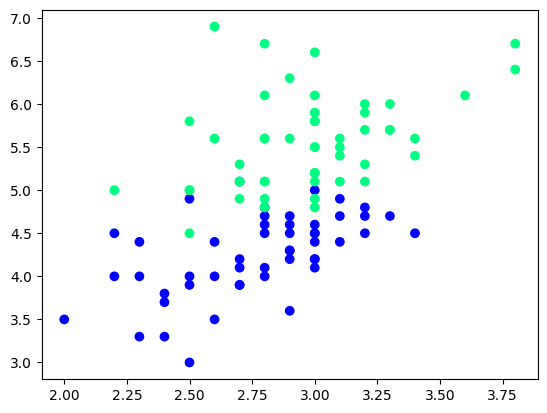

In [14]:
import matplotlib.pyplot as plt
plt.scatter(df['sepal_width'],df['petal_length'],c=df['species'],cmap='winter')

In [15]:
df.shape

(100, 3)

In [16]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [17]:
df_train

,sepal_width,petal_length,species
98,2.5,3.0,1
53,2.3,4.0,1
77,3.0,5.0,1
127,3.0,4.9,2
52,3.1,4.9,1
115,3.2,5.3,2
101,2.7,5.1,2
138,3.0,4.8,2
80,2.4,3.8,1
55,2.8,4.5,1


In [18]:
df_val

,sepal_width,petal_length,species
132,2.8,5.6,2
104,3.0,5.8,2
137,3.1,5.5,2
134,2.6,5.6,2
147,3.0,5.2,2


In [19]:
df_test

,sepal_width,petal_length,species
145,3.0,5.2,2
141,3.1,5.1,2
57,2.4,3.3,1
146,2.5,5.0,2
78,2.9,4.5,1


In [20]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [22]:
print(X_test)
print(y_test)

[[2.8 5.6]
 [3.  5.8]
 [3.1 5.5]
 [2.6 5.6]
 [3.  5.2]]
[2 2 2 2 2]


## Case 1 - Bagging

In [23]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_width,petal_length,species
138,3.0,4.8,2
55,2.8,4.5,1
53,2.3,4.0,1
52,3.1,4.9,1
55,2.8,4.5,1
127,3.0,4.9,2
98,2.5,3.0,1
53,2.3,4.0,1


In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [25]:
dt_bag1 = DecisionTreeClassifier()

In [26]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

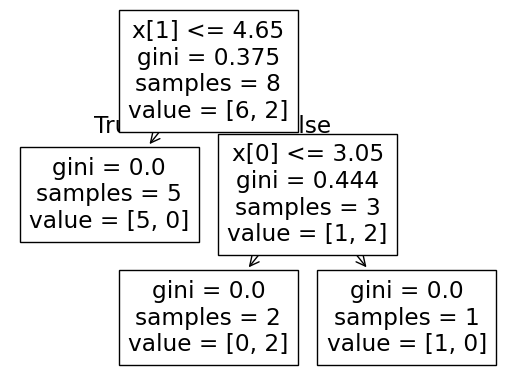

C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


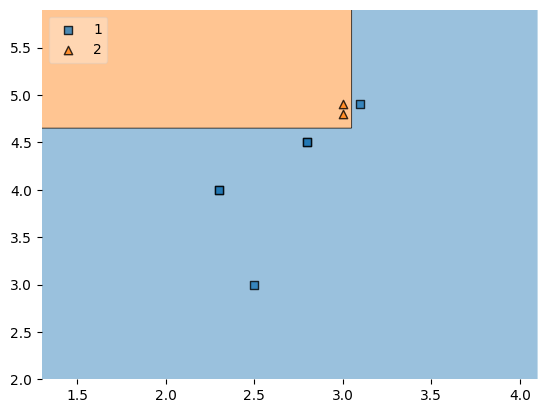

In [27]:
evaluate(dt_bag1,X,y)

In [28]:
# Data for Tree 2
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal_width,petal_length,species
80,2.4,3.8,1
138,3.0,4.8,2
55,2.8,4.5,1
80,2.4,3.8,1
98,2.5,3.0,1
115,3.2,5.3,2
52,3.1,4.9,1
52,3.1,4.9,1


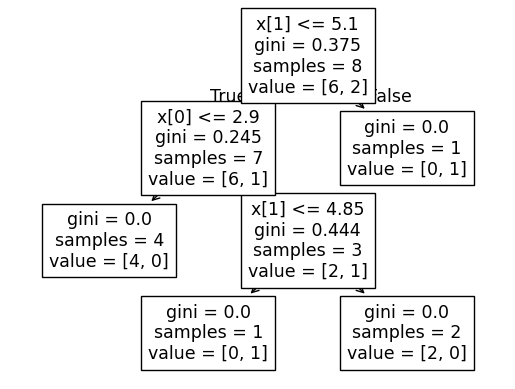

C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


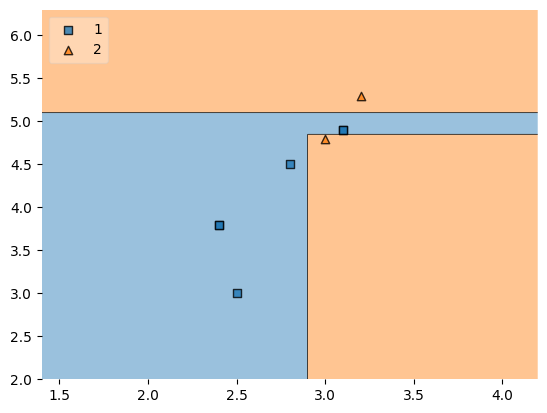

In [29]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [30]:
# Data for Tree 3
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal_width,petal_length,species
101,2.7,5.1,2
115,3.2,5.3,2
101,2.7,5.1,2
77,3.0,5.0,1
80,2.4,3.8,1
101,2.7,5.1,2
77,3.0,5.0,1
52,3.1,4.9,1


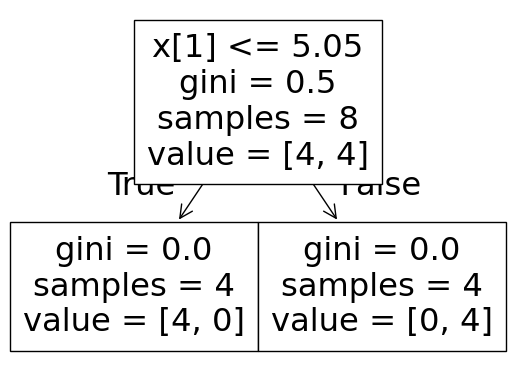

C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


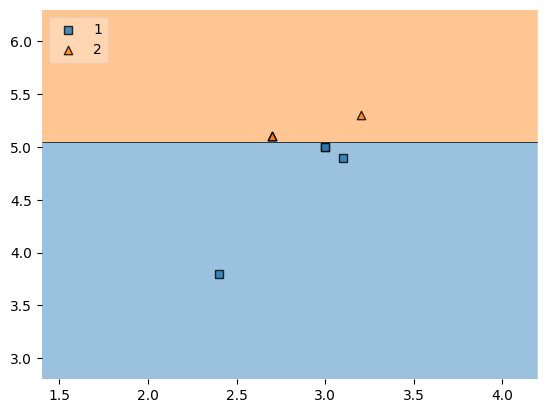

In [31]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

## Predict

In [33]:
df_test

,sepal_width,petal_length,species
145,3.0,5.2,2
141,3.1,5.1,2
57,2.4,3.3,1
146,2.5,5.0,2
78,2.9,4.5,1


In [36]:
print("Predictor 1",dt_bag1.predict(np.array([2.9,4.5]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.9,4.5]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.9,4.5]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [2]
Predictor 3 [1]


C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


## case 2 - Pasting

In [37]:
# Row sampling without replacement
df_train

,sepal_width,petal_length,species
98,2.5,3.0,1
53,2.3,4.0,1
77,3.0,5.0,1
127,3.0,4.9,2
52,3.1,4.9,1
115,3.2,5.3,2
101,2.7,5.1,2
138,3.0,4.8,2
80,2.4,3.8,1
55,2.8,4.5,1


In [38]:
df_train.sample(8)


,sepal_width,petal_length,species
52,3.1,4.9,1
55,2.8,4.5,1
127,3.0,4.9,2
98,2.5,3.0,1
77,3.0,5.0,1
101,2.7,5.1,2
53,2.3,4.0,1
138,3.0,4.8,2


## case 3 - Random Subspaces

In [51]:
#columns sampling with replacement or without replacemrnt
df1 = sns.load_dataset('iris')

In [52]:
df1.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [53]:
df1.sample(2,replace=True,axis=1)

,species,petal_length
0,setosa,1.4
1,setosa,1.4
2,setosa,1.3
3,setosa,1.5
4,setosa,1.4
...,...,...
145,virginica,5.2
146,virginica,5.0
147,virginica,5.2
148,virginica,5.4


## case 4 - Random Patches

In [54]:
#both rows and columns sampling
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,species,petal_length
34,setosa,1.5
13,setosa,1.1
49,setosa,1.4
96,versicolor,4.2
111,virginica,5.3
66,versicolor,4.5
71,versicolor,4.0
77,versicolor,5.0
